# Notebook 04 – Preprocessing and Date-Based Train/Test Split

## What is this notebook for?
We prepare the final feature matrices and split the data by date.  
Training uses only past years; testing uses later years.

## Why do we need this stage?
- A random split on monthly price data lets the model “see the future”.
- By cutting at a fixed date we get an honest estimate of how the model will perform on new months.


## Step 4.1 – Load the file that already has lag features


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../data/processed/uganda_maize_beans_with_lags.csv', parse_dates=['date'])
df = df.sort_values(['date', 'market']).reset_index(drop=True)
print("Full data with lags – shape:", df.shape)
print("Date range:", df['date'].min().date(), "to", df['date'].max().date())


Full data with lags – shape: (1233, 23)
Date range: 2008-10-15 to 2026-04-15


## Step 4.2 – Define the feature lists


In [2]:
maize_feats = [
    'maize_price_lag1', 'maize_price_lag2', 'maize_price_lag3',
    'maize_price_lag6', 'maize_price_lag12', 'maize_price_roll3',
    'beans_price_lag1', 'month_sin', 'month_cos',
    'latitude', 'longitude', 'year', 'month'
]
beans_feats = [
    'beans_price_lag1', 'beans_price_lag2', 'beans_price_lag3',
    'beans_price_lag6', 'beans_price_lag12', 'beans_price_roll3',
    'maize_price_lag1', 'month_sin', 'month_cos',
    'latitude', 'longitude', 'year', 'month'
]
print("Maize features:", maize_feats)
print("\nBeans features:", beans_feats)


Maize features: ['maize_price_lag1', 'maize_price_lag2', 'maize_price_lag3', 'maize_price_lag6', 'maize_price_lag12', 'maize_price_roll3', 'beans_price_lag1', 'month_sin', 'month_cos', 'latitude', 'longitude', 'year', 'month']

Beans features: ['beans_price_lag1', 'beans_price_lag2', 'beans_price_lag3', 'beans_price_lag6', 'beans_price_lag12', 'beans_price_roll3', 'maize_price_lag1', 'month_sin', 'month_cos', 'latitude', 'longitude', 'year', 'month']


## Step 4.3 – Drop rows that still have missing lag values


In [3]:
maize_df = df.dropna(subset=['maize_price', 'maize_price_lag1']).copy()
print("Maize usable rows:", len(maize_df))
print("Maize date range :", maize_df['date'].min().date(), "to", maize_df['date'].max().date())

beans_df = df.dropna(subset=['beans_price', 'beans_price_lag1']).copy()
print("\nBeans usable rows:", len(beans_df))
print("Beans date range :", beans_df['date'].min().date(), "to", beans_df['date'].max().date())


Maize usable rows: 1140
Maize date range : 2011-05-15 to 2026-04-15

Beans usable rows: 1214
Beans date range : 2008-11-15 to 2026-04-15


## Step 4.4 – Date-based split (the critical fix)
Train: all months up to December 2022.  
Test: all months from January 2023 onwards.


In [4]:
train_m = maize_df[maize_df['date'] <= '2022-12-31'].copy()
test_m  = maize_df[maize_df['date'] >= '2023-01-01'].copy()
print("=== MAIZE ===")
print("Train rows:", len(train_m), "| from", train_m['date'].min().date(), "to", train_m['date'].max().date())
print("Test  rows:", len(test_m),  "| from", test_m['date'].min().date(),  "to", test_m['date'].max().date())

train_b = beans_df[beans_df['date'] <= '2022-12-31'].copy()
test_b  = beans_df[beans_df['date'] >= '2023-01-01'].copy()
print("\n=== BEANS ===")
print("Train rows:", len(train_b), "| from", train_b['date'].min().date(), "to", train_b['date'].max().date())
print("Test  rows:", len(test_b),  "| from", test_b['date'].min().date(),  "to", test_b['date'].max().date())


=== MAIZE ===
Train rows: 828 | from 2011-05-15 to 2022-12-15
Test  rows: 312 | from 2023-01-15 to 2026-04-15

=== BEANS ===
Train rows: 886 | from 2008-11-15 to 2022-12-15
Test  rows: 328 | from 2023-01-15 to 2026-04-15


## Step 4.5 – Graph 1: Train vs Test sizes


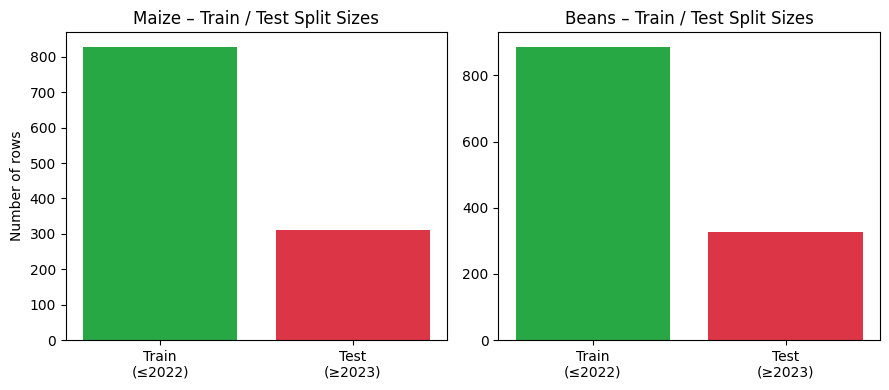

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(['Train\n(≤2022)', 'Test\n(≥2023)'], [len(train_m), len(test_m)], color=['#28A745', '#DC3545'])
axes[0].set_title('Maize – Train / Test Split Sizes')
axes[0].set_ylabel('Number of rows')
axes[1].bar(['Train\n(≤2022)', 'Test\n(≥2023)'], [len(train_b), len(test_b)], color=['#28A745', '#DC3545'])
axes[1].set_title('Beans – Train / Test Split Sizes')
plt.tight_layout()
plt.savefig('../figures/04_train_test_sizes.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 4.6 – Graph 2: Price series with the split date marked


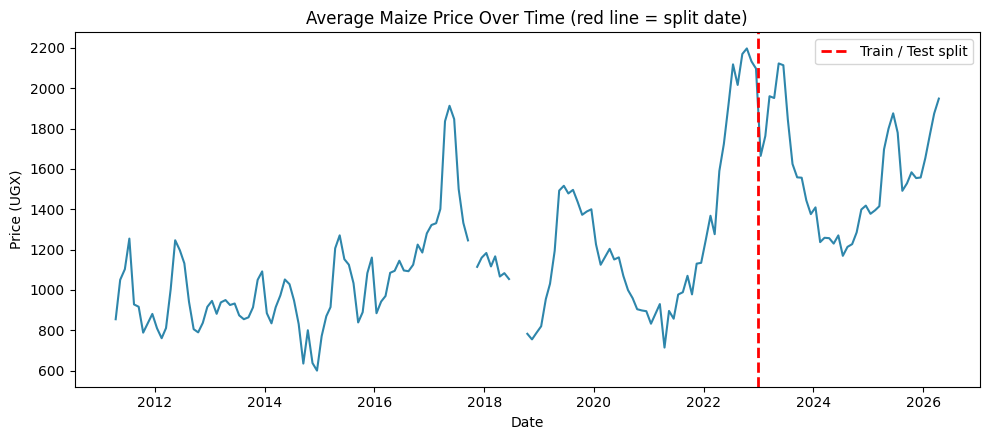

In [6]:
plt.figure(figsize=(10, 4.5))
avg_m = df.groupby('date')['maize_price'].mean()
plt.plot(avg_m.index, avg_m.values, color='#2E86AB', lw=1.5)
plt.axvline(pd.Timestamp('2022-12-31'), color='red', ls='--', lw=2, label='Train / Test split')
plt.title('Average Maize Price Over Time (red line = split date)')
plt.xlabel('Date'); plt.ylabel('Price (UGX)'); plt.legend()
plt.tight_layout()
plt.savefig('../figures/04_split_illustration.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 4.7 – Graph 3: Beans price series with the split date marked


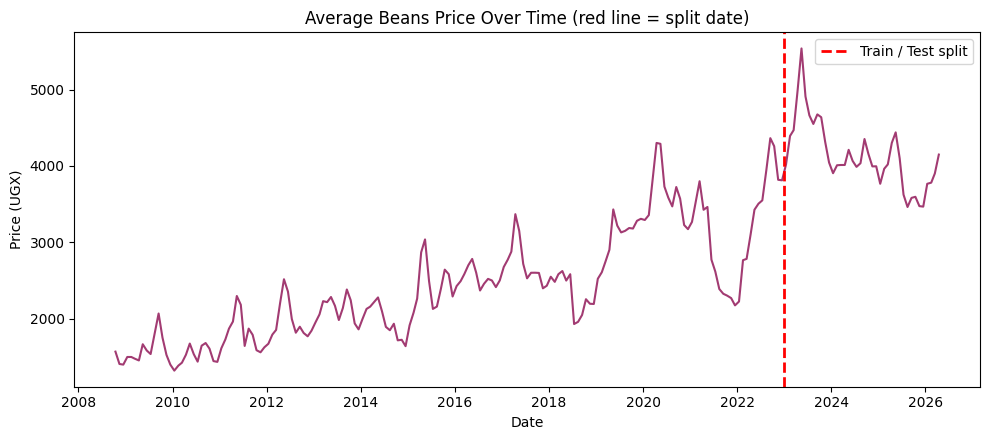

In [7]:
plt.figure(figsize=(10, 4.5))
avg_b = df.groupby('date')['beans_price'].mean()
plt.plot(avg_b.index, avg_b.values, color='#A23B72', lw=1.5)
plt.axvline(pd.Timestamp('2022-12-31'), color='red', ls='--', lw=2, label='Train / Test split')
plt.title('Average Beans Price Over Time (red line = split date)')
plt.xlabel('Date'); plt.ylabel('Price (UGX)'); plt.legend()
plt.tight_layout()
plt.savefig('../figures/04_beans_split_illustration.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 4.8 – Save the train and test files


In [8]:
train_m.to_csv('../data/processed/train_maize.csv', index=False)
test_m.to_csv('../data/processed/test_maize.csv', index=False)
train_b.to_csv('../data/processed/train_beans.csv', index=False)
test_b.to_csv('../data/processed/test_beans.csv', index=False)
print("Saved four files in data/processed/")


Saved four files in data/processed/
